In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("/content/High_Volume_Weekly_DS.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (500, 59)


,ItemID,Description,Bottles_Per_Case,Cost_Amount_Per_Bottle,Total_Cost,Week1,Week2,Week3,Week4,Week5,...,Week45,Week46,Week47,Week48,Week49,Week50,Week51,Week52,Week53,Grand_Total
0,18467,SCOTTY'S VODKA 50ML,96,0.990000,95.04,60,93,93,94,89,...,164,170,159,137,99,118,163,102,76,7690
1,96741,CORONA EXTRA 4/6 NR - 12OZ,24,1.831667,43.96,162,0,0,144,144,...,180,174,216,294,102,114,126,252,114,7478
2,70417,FIREBALL CINN WHISKY 50ML/10PK LOOSE,120,1.090000,130.80,62,170,170,108,166,...,152,0,0,147,81,0,71,169,0,7520
3,249230,FIREBALL WHISKY 10PK SLV - 50ML,120,1.090000,130.80,230,100,100,280,210,...,210,140,120,280,150,290,0,0,0,7391
4,35211,SMIRNOFF VODKA - 50ML,120,0.990000,118.80,142,181,181,154,167,...,160,174,113,155,165,219,157,99,45,7404


## Step 2 — Create the features
Here's where we turn 53 weeks of sales into three measurements describing each product.

In [3]:
weeks = [f"Week{i}" for i in range(1, 54)]

# Create a new dataset for clustering
products = df[["ItemID", "Description"]].copy()

products["Total_Sales"] = df[weeks].sum(axis=1)
products["Avg_Weekly_Sales"] = df[weeks].mean(axis=1)
products["Sales_SD"] = df[weeks].std(axis=1)
products["Zero_Sales_Pct"] = (df[weeks] == 0).mean(axis=1) * 100

# Exclude products with no recorded sales
products = products[products["Total_Sales"] > 0].copy()

display(products.head())
print("Products remaining:", len(products))

,ItemID,Description,Total_Sales,Avg_Weekly_Sales,Sales_SD,Zero_Sales_Pct
0,18467,SCOTTY'S VODKA 50ML,7593,143.264151,52.179848,0.000000
1,96741,CORONA EXTRA 4/6 NR - 12OZ,7452,140.603774,65.277614,5.660377
2,70417,FIREBALL CINN WHISKY 50ML/10PK LOOSE,7399,139.603774,60.087865,7.547170
3,249230,FIREBALL WHISKY 10PK SLV - 50ML,7270,137.169811,77.020910,13.207547
4,35211,SMIRNOFF VODKA - 50ML,7283,137.415094,63.173885,3.773585


Products remaining: 443


We're excluding the 57 products with no recorded weekly sales so they don't dominate a cluster simply because they're all zeros.

## Step 3 — Standardize the features

In [7]:
features = [
    "Avg_Weekly_Sales",
    "Sales_SD",
    "Zero_Sales_Pct"
]

scaler = StandardScaler()
X = scaler.fit_transform(products[features])

StandardScaler() puts the features on comparable scales, so one variable doesn't dominate just because its numbers are bigger.

In [8]:
k_values = range(2,11)
inertias = []

for k in k_values:
  model = KMeans(n_clusters=k, random_state=42, n_init=20)

## Step 4 — Finding a reasonable k using the elbow method

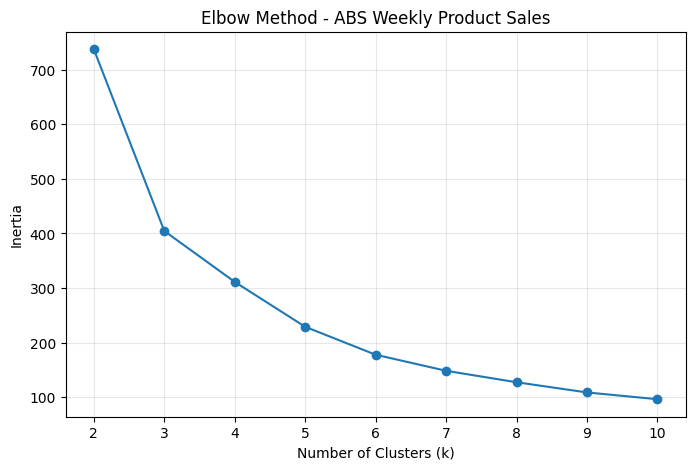

In [17]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - ABS Weekly Product Sales")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

In [19]:
# Step 5: Perform K-Means Clustering

# Choose the number of clusters
k = 4

# Create the K-Means model
model = KMeans(n_clusters=k, random_state=42, n_init=20)

# Fit the model and assign each product to a cluster
products["Cluster"] = model.fit_predict(X)

# Summarize each cluster
cluster_summary = products.groupby("Cluster").agg(
    Products=("ItemID", "count"),
    Avg_Weekly_Sales=("Avg_Weekly_Sales", "mean"),
    Sales_SD=("Sales_SD", "mean"),
    Zero_Sales_Pct=("Zero_Sales_Pct", "mean")
).round(2)

# Display results
display(cluster_summary)

,Products,Avg_Weekly_Sales,Sales_SD,Zero_Sales_Pct
Cluster,,,,
0,318,14.83,8.50,6.23
1,59,12.47,19.47,55.39
2,50,54.36,33.09,10.42
3,16,117.42,55.29,3.89


I evaluated values of k ranging from 2 to 10 using the elbow method. Although the largest reduction in inertia occurred between two and three clusters, the curve continued to show meaningful improvement at four clusters. I compared the interpretability of three- and four-cluster solutions and selected k = 4 because it distinguished moderately high-volume products from exceptionally high-volume products while preserving separate groups for consistent and intermittent sellers. This additional distinction could help inventory planners identify products requiring different levels of monitoring.

- Cluster 0 – Low-Volume, Consistent Sellers (318 products): Low average weekly sales (14.83), minimal fluctuations (SD = 8.50), and few zero-sales weeks (6.23%).
- Cluster 1 – Intermittent Sellers (59 products): Low average sales (12.47), higher variability (SD = 19.47), and frequent zero-sales weeks (55.39%).
- Cluster 2 – High-Volume, Variable Sellers (50 products): Higher average weekly sales (54.36), considerable fluctuations (SD = 33.09), and occasional zero-sales weeks (10.42%).
- Cluster 3 – Very High-Volume Sellers (16 products): Highest average weekly sales (117.42), greatest absolute fluctuations (SD = 55.29), and very few zero-sales weeks (3.89%).

you can clearly see that the main differences between these clusters are how much the products sell, how much their sales fluctuate, and how often they have zero sales. Cluster 0 contains products with lower but consistent sales, while Cluster 1 has products that sell less frequently and have more unpredictable sales. Cluster 2 contains higher-selling products with more fluctuations, and Cluster 3 represents the highest-selling products with very few weeks of zero sales. This shows that products can have very different sales patterns, which could help ABS make better inventory decisions.

## 5. Creating a visualization for the article

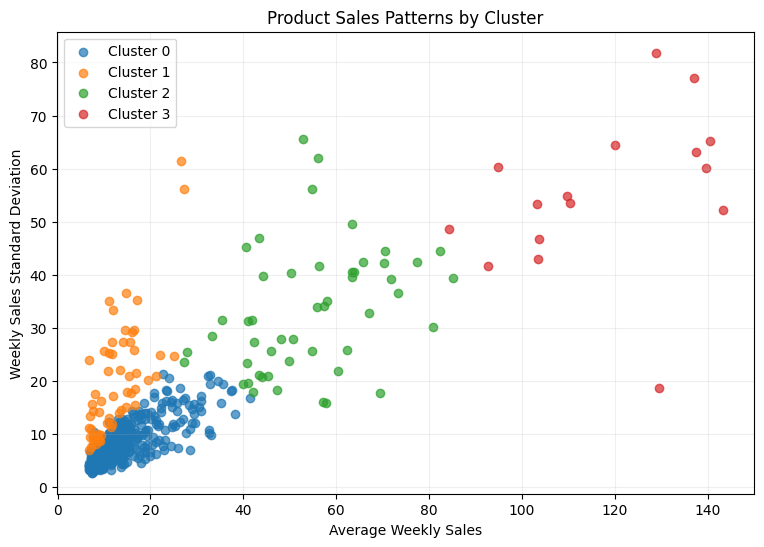

In [20]:
plt.figure(figsize=(9, 6))

for cluster in sorted(products["Cluster"].unique()):
    subset = products[products["Cluster"] == cluster]

    plt.scatter(
        subset["Avg_Weekly_Sales"],
        subset["Sales_SD"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Average Weekly Sales")
plt.ylabel("Weekly Sales Standard Deviation")
plt.title("Product Sales Patterns by Cluster")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

This graph compares average sales against variability, colored by the clusters.
NOTE: The Zero_Sales_Pct also influenced the clustering, even though it's not displayed on the two axes im visualizing.

First, what is the graph telling us?

Every single dot represents one alcohol product.
- X-axis (Average Weekly Sales): How many units the product sells per week, on average. Farther right = more sales.
- Y-axis (Weekly Sales Standard Deviation): How much sales fluctuate. Higher up = more variation.
- Colors: Which cluster K-means assigned the product to.


Blue (Cluster 0): Products grouped toward the bottom left. Lower sales and relatively little fluctuation.

Orange (Cluster 1): Generally low sales, but some products have much higher fluctuations than the blue products.

Green (Cluster 2): Higher sales and generally greater fluctuations.

Red (Cluster 3): Highest-selling products, many with large sales fluctuations.

## 6. Find two real products from each cluster

In [21]:
# Make random examples reproducible
examples = (
    products.groupby("Cluster", group_keys=False)
    .sample(n=2, random_state=42)
)

display(examples[
    ["Cluster", "ItemID", "Description",
     "Avg_Weekly_Sales", "Sales_SD", "Zero_Sales_Pct"]
])

,Cluster,ItemID,Description,Avg_Weekly_Sales,Sales_SD,Zero_Sales_Pct
146,0,241601,DOGFISH HEAD BAR CART VARIETY PACK - 3/8 CAN,19.169811,14.062684,13.207547
433,0,35327,GILBEY'S VODKA - 750ML,7.716981,3.477274,0.000000
135,1,23193,GUINNESS STOUT 2/12 NR,21.283019,20.869906,30.188679
446,1,170928,HAPPY DAD HARD SELTZER VARIETY PK 2/12 CAN 12OZ,7.698113,14.333373,69.811321
51,2,248077,SURFSIDE LEMONADE VARIETY PACK 3/8PK 12OZ CAN,43.471698,47.028880,43.396226
46,2,30965,MODELO ORO 2/12 CAN,48.226415,27.894473,5.660377
7,3,359430,FIREBALL CINNAMON WHISKY CARRIER - 6/50ML,120.000000,64.418105,1.886792
14,3,38113,BACARDI SUP WHITE RUM - 50ML,92.754717,41.698970,1.886792


Cluster 0 — Lower-volume, consistent sellers

318 products in the cluster

Dogfish Head Bar Cart Variety Pack: Average 19.17 units/week, SD 14.06, and 13.21% zero-sales weeks.

Gilbey's Vodka 750ML: Average 7.72 units/week, SD 3.48, and 0% zero-sales weeks.
These products have relatively low weekly sales and generally consistent demand compared with higher-volume groups.

---

Cluster 1 — Intermittent sellers

59 products in the cluster

Guinness Stout: Average 21.28 units/week, SD 20.87, and 30.19% zero-sales weeks.
Happy Dad Hard Seltzer: Average 7.70 units/week, SD 14.33, and 69.81% zero-sales weeks.

Both show inconsistent sales, especially Happy Dad, which recorded zero sales in nearly 70% of weeks!

They both average approximately 7.7 units per week.

BUT:
- Gilbey's has 0% zero-sales weeks.
- Happy Dad has 69.81% zero-sales weeks.

THEY have ALMOST the same average sales, yet there weekly sales patterns are different!

---
Cluster 2 — Higher-volume, variable sellers

50 products in the cluster

Surfside Lemonade Variety Pack: Average 43.47 units/week, SD 47.03, and 43.40% zero-sales weeks.

Modelo Oro: Average 48.23 units/week, SD 27.89, and 5.66% zero-sales weeks.

These products have similar average sales but noticeably different zero-sales frequencies. This shows that individual products within the same cluster can still differ!

---
Cluster 3 — Very high-volume sellers

16 products in the cluster

Fireball Cinnamon Whisky Carrier: Average 120 units/week, SD 64.42, and 1.89% zero-sales weeks.

Bacardi Superior White Rum 50ML: Average 92.75 units/week, SD 41.70, and 1.89% zero-sales weeks.

These products sell at very high volumes, rarely record zero-sales weeks, and have large absolute fluctuations.

## Final Results and Conclusion

After using K-means clustering, I was able to identify four different groups of products based on their weekly sales, how much their sales fluctuate, and how often they have zero sales.

One thing I found especially interesting was that products with similar average sales don't always have similar sales patterns! For example, Gilbey's Vodka and Happy Dad Hard Seltzer both averaged around 7.7 units per week, but Happy Dad had zero sales in nearly 70% of weeks, while Gilbey's had sales every week.

#### So, what can ABS actually do with these findings?

If I were presenting this to ABS, I would recommend using these clusters to help guide inventory planning. Products with consistently high sales could be monitored more frequently to avoid running out of stock, while products with unpredictable sales could be investigated further before deciding how much to reorder. For products with lower but steady sales, ABS could explore smaller, more consistent replenishment orders.

Of course, we would still need to consider stock availability, delivery times, and seasonal demand before making actual ordering decisions.

Overall, I think this analysis shows that understanding how products sell is just as important as knowing how much they sell. Rather than treating every product the same, ABS could use these patterns as a starting point for making smarter, more informed inventory decisions!